In [1]:
!pip -q install segmentation-models-pytorch
!ls /kaggle/input
!nvidia-smi -L
!df -h /tmp /kaggle/working | cat

import torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| GPUs:", torch.cuda.device_count())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.2 MB/s eta 0:00:00
datasets
GPU 0: Tesla T4 (UUID: GPU-7560dfeb-2d4f-ae2d-b1ef-37999e3a0bc1)
GPU 1: Tesla T4 (UUID: GPU-376fbc8d-d5e6-0298-3bbe-99a52f9f7711)
Filesystem      Size  Used Avail Use% Mounted on
overlay         8.0T  7.0T  1.1T  87% /
/dev/loop2       20G  108K   20G   1% /kaggle/working
torch 2.11.0+cu128 | CUDA: True | GPUs: 2


In [2]:
import os, random, time, shutil, warnings
from functools import partial
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm as _tqdm
from scipy.signal import find_peaks, medfilt
from sklearn.metrics import roc_auc_score, roc_curve, r2_score
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
warnings.filterwarnings("ignore")
tqdm = partial(_tqdm, mininterval=30)          # fewer log lines in committed runs

# ---------- find the data automatically (only lists folders, opens no video) ----------
def find_file(name):
    for dp, _, fs in os.walk("/kaggle/input"):
        for f in fs:
            if f.lower() == name.lower():
                return os.path.join(dp, f)
    raise FileNotFoundError(f"{name} not found under /kaggle/input")

def find_video_dir():
    for dp, _, fs in os.walk("/kaggle/input"):
        if any(f.lower().endswith(".avi") for f in fs):
            return dp
    raise FileNotFoundError("No .avi files found under /kaggle/input")

FILELIST      = find_file("FileList.csv")
TRACINGS      = find_file("VolumeTracings.csv")
INPUT_VID_DIR = find_video_dir()                 # slow network-backed input folder
LOCAL_VID_DIR = "/tmp/echonet_videos"            # fast local copy (made in chunk 3)
VID_DIR       = LOCAL_VID_DIR                    # everything after chunk 3 reads from here
print("FileList :", FILELIST); print("Tracings :", TRACINGS); print("Videos   :", INPUT_VID_DIR)

OUT = "/kaggle/working"                          # saved outputs
RESUME_DIR = None                                # e.g. "/kaggle/input/my-previous-run" to resume EF training

# ---------- switches you may change ----------
DROP_ODD_SIZE_TRAIN = True     # drop the 768x1024 videos from TRAIN only
DROP_EXTREME_TRAIN  = False    # drop EDV/ESV > 400 mL videos from TRAIN only
IMG = 112                      # native video size
SEG_SIZE, SEG_EPOCHS, SEG_BS, SEG_LR = 128, 40, 32, 1e-3
FRAMES, PERIOD = 32, 2         # EF clip: 32 frames, every 2nd frame
EF_EPOCHS, EF_BS, EF_LR = 35, 16, 2e-4
NUM_WORKERS = min(4, os.cpu_count())
SEED = 42

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| GPUs:", torch.cuda.device_count(), "| CPU cores:", os.cpu_count())

def show(res):
    """Print a report dict nicely: the 'model' entry is text, so it is not rounded."""
    name = res.get("model", "")
    nums = pd.Series({k: v for k, v in res.items() if k != "model"}, dtype=float).round(4)
    print(f"--- {name} ---"); print(nums.to_string())

FileList : /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/FileList.csv
Tracings : /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/VolumeTracings.csv
Videos   : /kaggle/input/datasets/sahilsagramani/echonet-dynamic/EchoNet-Dynamic/Videos
Device: cuda | GPUs: 2 | CPU cores: 4


In [3]:
# ---------- Part A: one-time copy of the videos to fast local disk ----------
srcs = sorted(os.path.join(INPUT_VID_DIR, f) for f in os.listdir(INPUT_VID_DIR) if f.lower().endswith(".avi"))
print("videos found in input:", len(srcs))
os.makedirs(LOCAL_VID_DIR, exist_ok=True)
free_gb = shutil.disk_usage("/tmp").free / 1e9
print(f"free disk in /tmp: {free_gb:.1f} GB")
assert free_gb > 10, "Not enough free space in /tmp for the videos"

# speed test on 20 files (reads raw bytes only)
t = time.time()
for s in srcs[:20]:
    with open(s, "rb") as fh: fh.read()
per_file = (time.time() - t) / 20
print(f"read speed: {per_file:.3f} s/file -> about {per_file * len(srcs) / 60 / 16:.1f} min for all with 16+ threads (rough)")

def cp(s):
    d = os.path.join(LOCAL_VID_DIR, os.path.basename(s))
    if os.path.exists(d) and os.path.getsize(d) > 0:       # skip files already copied (safe to re-run)
        return None
    try:
        shutil.copyfile(s, d); return None
    except Exception as e:
        return (s, str(e))

with ThreadPoolExecutor(32) as ex:
    errs = [e for e in tqdm(ex.map(cp, srcs), total=len(srcs)) if e]
if errs:                                                    # one retry for failed files
    print("retrying", len(errs), "failed files")
    errs = [e for e in (cp(s) for s, _ in errs) if e]
print("copied:", len(os.listdir(LOCAL_VID_DIR)), "| still failing:", len(errs))

# ---------- Part B: load CSVs, map paths, audit (no video is opened for the audit) ----------
fl = pd.read_csv(FILELIST)
vt = pd.read_csv(TRACINGS)
vt["FileName"] = vt["FileName"].str.replace(".avi", "", regex=False)

vid_map = {os.path.splitext(f)[0].upper(): os.path.join(LOCAL_VID_DIR, f)
           for f in os.listdir(LOCAL_VID_DIR) if f.lower().endswith(".avi")}
fl["path"]   = fl.FileName.str.upper().map(vid_map)
fl["exists"] = fl.path.notna()

fl["odd_size"]  = (fl.FrameHeight != IMG) | (fl.FrameWidth != IMG)     # sizes come from the CSV
fl["extreme"]   = (fl.EDV > 400) | (fl.ESV > 400)
fl["has_trace"] = fl.FileName.isin(set(vt.FileName))

print("\nvideos in FileList        :", len(fl))
print("missing video files       :", (~fl.exists).sum())
print("NaNs / duplicate names    :", fl.isna().sum().drop("path").sum(), "/", fl.FileName.duplicated().sum())
print("EF formula max error      :", ((fl.EDV - fl.ESV) / fl.EDV * 100 - fl.EF).abs().max())
print("odd-size videos           :", fl[fl.exists].odd_size.sum(), fl[fl.exists & fl.odd_size].Split.value_counts().to_dict())
print("videos < 32 frames        :", ((fl.NumberOfFrames < FRAMES) & fl.exists).sum())
print("extreme volume videos     :", fl.extreme.sum())
print("videos without tracings   :", (~fl.has_trace).sum())
print("tracing names not in list :", len(set(vt.FileName) - set(fl.FileName)))
print("rows per traced frame     :\n", vt.groupby(["FileName", "Frame"]).size().value_counts().head(8))
print(fl.Split.value_counts().to_dict())

# ---------- Part C: spot-check that the CSV metadata matches the real files ----------
def probe(p):
    cap = cv2.VideoCapture(p)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)); h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); cap.release()
    return w, h, n

sample = pd.concat([fl[fl.exists & fl.odd_size], fl[fl.exists & ~fl.odd_size].sample(30, random_state=0)])
bad = 0
for r in sample.itertuples():
    w, h, n = probe(r.path)
    if (w, h) != (r.FrameWidth, r.FrameHeight) or abs(n - r.NumberOfFrames) > 1:
        bad += 1; print("mismatch:", r.FileName, (w, h, n), "vs CSV", (r.FrameWidth, r.FrameHeight, r.NumberOfFrames))
print(f"spot-check: {len(sample)} videos checked, {bad} mismatches")

videos found in input: 10030
free disk in /tmp: 1146.0 GB
read speed: 1.635 s/file -> about 17.1 min for all with 16+ threads (rough)


  0%|          | 0/10030 [00:00<?, ?it/s]

copied: 10030 | still failing: 0

videos in FileList        : 10030
missing video files       : 0
NaNs / duplicate names    : 0 / 0
EF formula max error      : 6.559737819600286e-08
odd-size videos           : 6 {'TRAIN': 5, 'TEST': 1}
videos < 32 frames        : 3
extreme volume videos     : 7
videos without tracings   : 6
tracing names not in list : 1
rows per traced frame     :
 21     19942
42        49
63        38
84        14
105        2
18         1
16         1
41         1
Name: count, dtype: int64
{'TRAIN': 7465, 'VAL': 1288, 'TEST': 1277}
mismatch: 0X5DD5283AC43CCDD1 (112, 112, 188) vs CSV (1024, 768, 188)
mismatch: 0X234005774F4CB5CD (112, 112, 127) vs CSV (1040, 768, 127)
mismatch: 0X2DC68261CBCC04AE (112, 112, 66) vs CSV (1024, 768, 66)
mismatch: 0X35291BE9AB90FB89 (112, 112, 208) vs CSV (1024, 768, 208)
mismatch: 0X6C435C1B417FDE8A (112, 112, 166) vs CSV (1024, 768, 166)
mismatch: 0X5515B0BD077BE68A (112, 112, 126) vs CSV (1024, 768, 126)
spot-check: 36 videos checked,

In [4]:
def block_to_poly(b):
    """b = 21 rows. Row 0 = long axis. Rows 1..20 = left/right wall points."""
    left  = b[["X1", "Y1"]].values[1:]
    right = b[["X2", "Y2"]].values[1:][::-1]
    return np.clip(np.concatenate([left, right], 0), 0, IMG - 1)

def poly_area(p):
    x, y = p[:, 0], p[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

# ---------- EF table (all videos used for EF regression) ----------
ef_df = fl[fl.exists].copy()
drop = pd.Series(False, index=ef_df.index)
if DROP_ODD_SIZE_TRAIN: drop |= (ef_df.Split == "TRAIN") & ef_df.odd_size
if DROP_EXTREME_TRAIN:  drop |= (ef_df.Split == "TRAIN") & ef_df.extreme
ef_df = ef_df[~drop].reset_index(drop=True)
print("EF table:", ef_df.Split.value_counts().to_dict())

# ---------- Segmentation table (only videos with clean tracings) ----------
valid = set(fl[fl.exists & ~fl.odd_size].FileName)
POLY, seg_rows, dropped = {}, [], []
for name, g in vt.groupby("FileName"):
    if name not in valid:
        dropped.append((name, "not usable video")); continue
    frames = sorted(g.Frame.unique())
    if len(frames) != 2:
        dropped.append((name, "frames != 2")); continue
    blocks = []
    for fr in frames:
        b = g[g.Frame == fr]
        if len(b) % 21 != 0:
            blocks = None; break
        blocks.append((fr, b.iloc[:21]))            # duplicated blocks -> keep the first one
    if blocks is None:
        dropped.append((name, "irregular rows")); continue
    polys = [block_to_poly(b) for _, b in blocks]
    areas = [poly_area(p) for p in polys]
    ed, es = (0, 1) if areas[0] >= areas[1] else (1, 0)    # larger area = end-diastole
    POLY[(name, "ED")], POLY[(name, "ES")] = polys[ed], polys[es]
    seg_rows.append(dict(FileName=name, ED_frame=int(blocks[ed][0]), ES_frame=int(blocks[es][0])))

seg_df = pd.DataFrame(seg_rows).merge(fl[["FileName", "Split"]], on="FileName")
print("Seg table:", seg_df.Split.value_counts().to_dict(), "| dropped:", len(dropped))
print(pd.DataFrame(dropped, columns=["file", "reason"]).reason.value_counts().to_dict())

EF table: {'TRAIN': 7460, 'VAL': 1288, 'TEST': 1277}
Seg table: {'TRAIN': 7458, 'VAL': 1288, 'TEST': 1276} | dropped: 3
{'irregular rows': 2, 'not usable video': 1}


  0%|          | 0/10022 [00:00<?, ?it/s]

(20044, 112, 112) (20044, 112, 112) {'TRAIN': 14916, 'VAL': 2576, 'TEST': 2552}


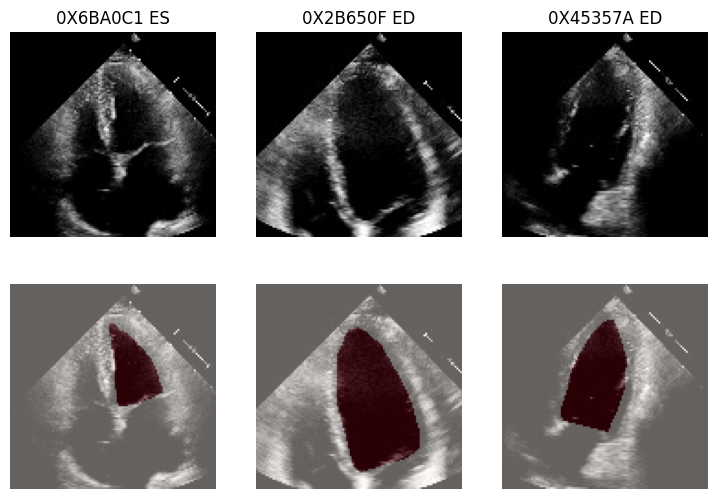

In [5]:
path_of = dict(zip(fl.FileName, fl.path))

def read_video(path, size=IMG, max_frames=None):
    """Return (T, size, size) uint8 grayscale frames; resize if the video is not size x size."""
    cap, frames = cv2.VideoCapture(path), []
    while True:
        ok, f = cap.read()
        if not ok: break
        g = cv2.cvtColor(f, cv2.COLOR_BGR2GRAY)
        if g.shape != (size, size):
            g = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)
        frames.append(g)
        if max_frames and len(frames) >= max_frames: break
    cap.release()
    return np.stack(frames)

def make_item(row):
    name = row.FileName
    v = read_video(path_of[name], max_frames=max(row.ED_frame, row.ES_frame) + 1)
    items = []
    for ph, fr in (("ED", row.ED_frame), ("ES", row.ES_frame)):
        if fr >= len(v): return None
        m = np.zeros((IMG, IMG), np.uint8)
        cv2.fillPoly(m, [np.round(POLY[(name, ph)]).astype(np.int32)], 1)
        items.append((v[fr], m, name, ph, row.Split))
    return items

rows = list(seg_df.itertuples(index=False))
with ThreadPoolExecutor(8) as ex:
    results = list(tqdm(ex.map(make_item, rows), total=len(rows)))
items = [i for r in results if r is not None for i in r]

SX = np.stack([i[0] for i in items]); SY = np.stack([i[1] for i in items])
smeta = pd.DataFrame([(i[2], i[3], i[4]) for i in items], columns=["name", "phase", "split"])
np.savez_compressed(f"{OUT}/seg_cache.npz", X=SX, Y=SY)
smeta.to_csv(f"{OUT}/seg_meta.csv", index=False)
print(SX.shape, SY.shape, smeta.split.value_counts().to_dict())

fig, ax = plt.subplots(2, 3, figsize=(9, 6))
for k, i in enumerate(np.random.choice(len(SX), 3, replace=False)):
    ax[0, k].imshow(SX[i], cmap="gray"); ax[0, k].set_title(f"{smeta.name[i][:8]} {smeta.phase[i]}")
    ax[1, k].imshow(SX[i], cmap="gray"); ax[1, k].imshow(SY[i], alpha=0.4, cmap="Reds")
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.show()

In [6]:
tr_idx = np.where(smeta.split == "TRAIN")[0]
va_idx = np.where(smeta.split == "VAL")[0]
te_idx = np.where(smeta.split == "TEST")[0]
MEAN = SX[tr_idx].mean() / 255.0
STD  = SX[tr_idx].std() / 255.0

def augment(img, m):
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), np.random.uniform(-10, 10), np.random.uniform(0.9, 1.1))
    M[:, 2] += np.random.uniform(-8, 8, 2)
    img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderValue=0)
    m   = cv2.warpAffine(m,   M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)
    img = img * np.random.uniform(0.8, 1.2) + np.random.uniform(-0.1, 0.1)
    img = img + np.random.normal(0, 0.02, img.shape)
    return np.clip(img, 0, 1).astype(np.float32), m

class SegDS(Dataset):
    def __init__(self, idx, train): self.idx, self.train = idx, train
    def __len__(self): return len(self.idx)
    def __getitem__(self, k):
        i = self.idx[k]
        img = SX[i].astype(np.float32) / 255.0
        m   = SY[i].astype(np.float32)
        if self.train: img, m = augment(img, m)
        img = cv2.resize(img, (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_LINEAR)
        m   = cv2.resize(m,   (SEG_SIZE, SEG_SIZE), interpolation=cv2.INTER_NEAREST)
        img = (img - MEAN) / STD
        return torch.from_numpy(img).unsqueeze(0).float(), torch.from_numpy(m).unsqueeze(0).float()

seg_tr = DataLoader(SegDS(tr_idx, True),  batch_size=SEG_BS, shuffle=True,  num_workers=2, drop_last=True)
seg_va = DataLoader(SegDS(va_idx, False), batch_size=64, shuffle=False, num_workers=2)
seg_te = DataLoader(SegDS(te_idx, False), batch_size=64, shuffle=False, num_workers=2)
print(len(tr_idx), len(va_idx), len(te_idx))

14916 2576 2552


In [7]:
import segmentation_models_pytorch as smp

def make_seg_model():
    try:
        return smp.Unet("efficientnet-b0", encoder_weights="imagenet", in_channels=1, classes=1)
    except Exception as e:
        print("EfficientNet-B0 failed, falling back to ResNet34:", e)
        return smp.Unet("resnet34", encoder_weights="imagenet", in_channels=1, classes=1)

def dice_loss(logits, y, eps=1e-6):
    p = torch.sigmoid(logits)
    inter = (p * y).sum((1, 2, 3)); den = p.sum((1, 2, 3)) + y.sum((1, 2, 3))
    return 1 - ((2 * inter + eps) / (den + eps)).mean()

@torch.no_grad()
def dice_iou(logits, y, th=0.5, eps=1e-6):
    p = (torch.sigmoid(logits) > th).float()
    inter = (p * y).sum((1, 2, 3)); union = p.sum((1, 2, 3)) + y.sum((1, 2, 3))
    return ((2 * inter + eps) / (union + eps)), ((inter + eps) / (union - inter + eps))

seg_model = make_seg_model().to(DEVICE)
opt = torch.optim.AdamW(seg_model.parameters(), lr=SEG_LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=SEG_EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
bce = nn.BCEWithLogitsLoss()
best_dice, seg_hist = 0.0, []

for ep in range(SEG_EPOCHS):
    seg_model.train(); tl = 0
    for x, y in tqdm(seg_tr, desc=f"seg ep{ep+1}", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad()
        with torch.autocast(device_type="cuda", enabled=DEVICE == "cuda"):
            lg = seg_model(x)
        lg = lg.float()
        loss = bce(lg, y) + dice_loss(lg, y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        tl += loss.item()
    sched.step()
    seg_model.eval(); ds = []
    with torch.no_grad():
        for x, y in seg_va:
            x, y = x.to(DEVICE), y.to(DEVICE)
            d, _ = dice_iou(seg_model(x).float(), y); ds.append(d.cpu())
    vd = torch.cat(ds).mean().item()
    seg_hist.append((ep + 1, tl / len(seg_tr), vd))
    print(f"ep {ep+1:02d} | train loss {tl/len(seg_tr):.4f} | val Dice {vd:.4f}", flush=True)
    if vd > best_dice:
        best_dice = vd; torch.save(seg_model.state_dict(), f"{OUT}/seg_best.pt")
print("Best val Dice:", best_dice)

config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

seg ep1:   0%|          | 0/466 [00:00<?, ?it/s]

ep 01 | train loss 0.2339 | val Dice 0.9121


seg ep2:   0%|          | 0/466 [00:00<?, ?it/s]

... (81 outputs left out)

seg ep39:   0%|          | 0/466 [00:00<?, ?it/s]

ep 39 | train loss 0.0917 | val Dice 0.9236


seg ep40:   0%|          | 0/466 [00:00<?, ?it/s]

ep 40 | train loss 0.0913 | val Dice 0.9236
Best val Dice: 0.9256190657615662


In [8]:
seg_model.load_state_dict(torch.load(f"{OUT}/seg_best.pt", map_location=DEVICE))
seg_model.eval(); D, I = [], []
with torch.no_grad():
    for x, y in seg_te:
        x, y = x.to(DEVICE), y.to(DEVICE)
        d, i = dice_iou(seg_model(x).float(), y); D.append(d.cpu()); I.append(i.cpu())
D, I = torch.cat(D).numpy(), torch.cat(I).numpy()

phase_te = smeta.phase.values[te_idx]
seg_results = {"Dice_all": D.mean(), "IoU_all": I.mean(),
               "Dice_ED": D[phase_te == "ED"].mean(), "Dice_ES": D[phase_te == "ES"].mean(),
               "IoU_ED": I[phase_te == "ED"].mean(),  "IoU_ES": I[phase_te == "ES"].mean()}
print(pd.Series(seg_results).round(4))
pd.Series(seg_results).to_csv(f"{OUT}/seg_test_results.csv")

Dice_all    0.9260
IoU_all     0.8656
Dice_ED     0.9383
Dice_ES     0.9136
IoU_ED      0.8852
IoU_ES      0.8459
dtype: float32


In [10]:
def report(y, p, name="model"):
    y, p = np.asarray(y, float), np.asarray(p, float)
    diff = p - y
    out = {"model": name, "MAE": np.abs(diff).mean(), "RMSE": np.sqrt((diff ** 2).mean()),
           "R2": r2_score(y, p), "BA_bias": diff.mean(), "BA_LoA(1.96sd)": 1.96 * diff.std()}
    for tag, lab, thr in (("EF<50", y < 50, 50), ("EF<=40", y <= 40, 40)):
        score = -p                                   # lower predicted EF = more likely reduced
        out[f"AUC_{tag}"] = roc_auc_score(lab, score)
        pred = p < thr if tag == "EF<50" else p <= thr
        out[f"Sens_{tag}"] = (pred & lab).sum() / max(lab.sum(), 1)
        out[f"Spec_{tag}"] = (~pred & ~lab).sum() / max((~lab).sum(), 1)
    return out

def plot_results(y, p, title):
    y, p = np.asarray(y), np.asarray(p)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    ax[0].scatter(y, p, s=5, alpha=0.4); ax[0].plot([5, 95], [5, 95], "r--")
    ax[0].set(xlabel="True EF (%)", ylabel="Predicted EF (%)", title=f"{title}: scatter")
    m, d = (y + p) / 2, p - y
    ax[1].scatter(m, d, s=5, alpha=0.4); ax[1].axhline(d.mean(), color="r")
    ax[1].axhline(d.mean() + 1.96 * d.std(), color="k", ls="--"); ax[1].axhline(d.mean() - 1.96 * d.std(), color="k", ls="--")
    ax[1].set(xlabel="Mean of true/pred", ylabel="Pred - True", title="Bland-Altman")
    for thr, tag in ((50, "EF<50"), (40, "EF<=40")):
        lab = (y < thr) if thr == 50 else (y <= thr)
        fpr, tpr, _ = roc_curve(lab, -p); ax[2].plot(fpr, tpr, label=f"{tag} AUC={roc_auc_score(lab, -p):.3f}")
    ax[2].plot([0, 1], [0, 1], "k--"); ax[2].legend(); ax[2].set(xlabel="FPR", ylabel="TPR", title="Reduced-EF ROC")
    plt.tight_layout(); plt.show()

  0%|          | 0/1288 [00:00<?, ?it/s]

  0%|          | 0/1277 [00:00<?, ?it/s]

NaN videos -> VAL: 0 | TEST: 0
--- U-Net area-based EF ---
MAE                5.1284
RMSE               6.9128
R2                 0.6803
BA_bias            0.0941
BA_LoA(1.96sd)    13.5478
AUC_EF<50          0.9333
Sens_EF<50         0.7614
Spec_EF<50         0.9264
AUC_EF<=40         0.9610
Sens_EF<=40        0.5688
Spec_EF<=40        0.9848


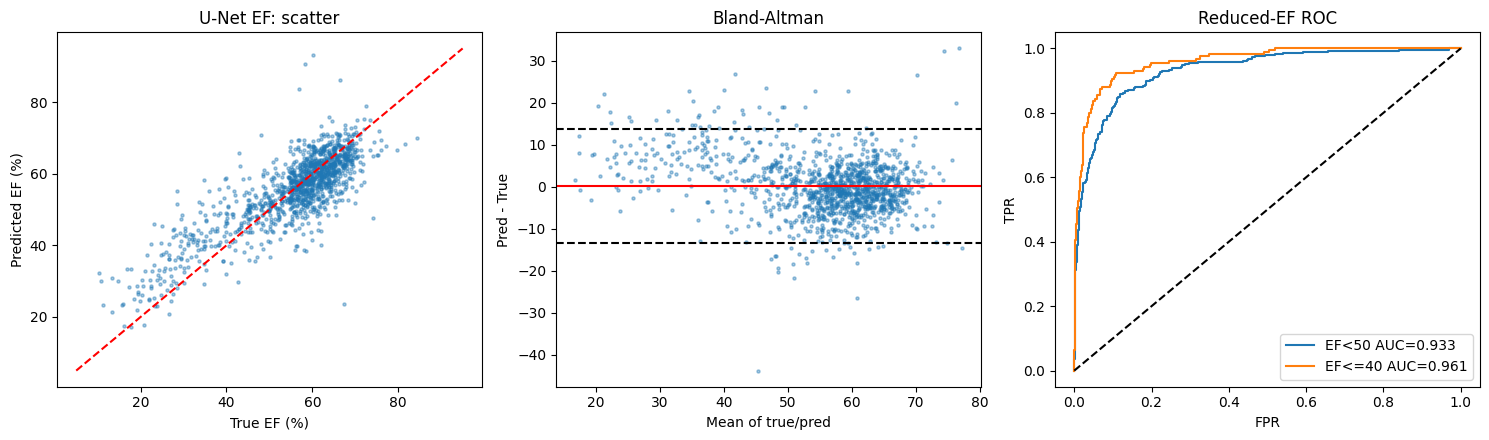

In [11]:
def show(res):
    """Print a report dict nicely: the 'model' entry is text, so it is not rounded."""
    name = res.get("model", "")
    nums = pd.Series({k: v for k, v in res.items() if k != "model"}, dtype=float).round(4)
    print(f"--- {name} ---"); print(nums.to_string())

@torch.no_grad()
def seg_areas(model, video):
    model.eval(); out = []
    for i in range(0, len(video), 128):
        x = video[i:i + 128].astype(np.float32) / 255.0
        x = np.stack([cv2.resize(f, (SEG_SIZE, SEG_SIZE)) for f in x])
        x = torch.from_numpy((x - MEAN) / STD).unsqueeze(1).float().to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=DEVICE == "cuda"):
            lg = model(x)
        out.append((torch.sigmoid(lg.float()) > 0.5).sum((1, 2, 3)).cpu().numpy())
    return np.concatenate(out).astype(np.float32)

def ef_from_areas(a, fps):
    a = medfilt(a, 3)
    rng = a.max() - a.min()
    if a.max() <= 0 or rng <= 0: return np.nan
    dist = max(3, int(0.4 * fps))
    pk, _ = find_peaks(a, distance=dist, prominence=0.1 * rng)       # end-diastole peaks
    tr, _ = find_peaks(-a, distance=dist, prominence=0.1 * rng)      # end-systole troughs
    eda = np.median(a[pk]) if len(pk) else a.max()
    esa = np.median(a[tr]) if len(tr) else a.min()
    return 100 * (1 - (esa / eda) ** 1.5)       # area -> volume proxy (V ~ A^1.5); pixel size cancels

def seg_ef_for(df):
    vals = []
    for r in tqdm(df.itertuples(), total=len(df)):
        v = read_video(r.path)
        vals.append(ef_from_areas(seg_areas(seg_model, v), r.FPS))
    return np.array(vals)

va_df = ef_df[ef_df.Split == "VAL"].reset_index(drop=True)
te_df = ef_df[ef_df.Split == "TEST"].reset_index(drop=True)
raw_va, raw_te = seg_ef_for(va_df), seg_ef_for(te_df)
np.save(f"{OUT}/unet_raw_val.npy", raw_va); np.save(f"{OUT}/unet_raw_test.npy", raw_te)   # save the slow results first

ok = ~np.isnan(raw_va)                           # linear calibration fitted on VAL only
print("NaN videos -> VAL:", (~ok).sum(), "| TEST:", np.isnan(raw_te).sum())
a_, b_ = np.polyfit(raw_va[ok], va_df.EF.values[ok], 1)
pred_te_seg = a_ * np.nan_to_num(raw_te, nan=np.nanmean(raw_va)) + b_

segEF_res = report(te_df.EF.values, pred_te_seg, "U-Net area-based EF")
show(segEF_res)
plot_results(te_df.EF.values, pred_te_seg, "U-Net EF")
pd.DataFrame({"FileName": te_df.FileName, "EF": te_df.EF, "pred": pred_te_seg}).to_csv(f"{OUT}/test_pred_unet.csv", index=False)

In [12]:
tr_df = ef_df[ef_df.Split == "TRAIN"].reset_index(drop=True)
EF_MEAN, EF_STD = tr_df.EF.mean(), tr_df.EF.std()
NEED = (FRAMES - 1) * PERIOD + 1      # 63 raw frames -> 32 sampled frames

class EFVideoDS(Dataset):
    def __init__(self, df, train, n_clips=1):
        self.paths = df.path.values; self.y = df.EF.values.astype(np.float32)
        self.train, self.n = train, n_clips
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        v = read_video(self.paths[i]); T = len(v)
        if T < NEED:                                             # pad short videos
            v = np.concatenate([v, np.repeat(v[-1:], NEED - T, 0)]); T = NEED
        if self.train:
            starts = [np.random.randint(0, T - NEED + 1)]
        elif self.n == 1:
            starts = [(T - NEED) // 2]
        else:
            starts = np.linspace(0, T - NEED, self.n).round().astype(int)
        clips = np.stack([v[s:s + NEED:PERIOD] for s in starts]).astype(np.float32) / 255.0   # (n,F,H,W)
        if self.train:
            clips = clips * np.random.uniform(0.8, 1.2) + np.random.uniform(-0.1, 0.1)
            pad = np.pad(clips, ((0, 0), (0, 0), (8, 8), (8, 8)))
            dy, dx = np.random.randint(0, 17, 2)
            clips = np.clip(pad[:, :, dy:dy + IMG, dx:dx + IMG], 0, 1)
        return torch.from_numpy(clips).unsqueeze(1).float(), torch.tensor(self.y[i])   # (n,1,F,H,W)

def make_loader(df, train, n_clips=1, bs=EF_BS):
    return DataLoader(EFVideoDS(df, train, n_clips), batch_size=bs, shuffle=train,
                      num_workers=NUM_WORKERS, pin_memory=True, drop_last=train,
                      persistent_workers=NUM_WORKERS > 0)

ef_tr = make_loader(tr_df, True)
ef_va = make_loader(va_df, False, n_clips=2, bs=8)
print(len(tr_df), len(va_df), len(te_df), "| EF mean/std:", round(EF_MEAN, 2), round(EF_STD, 2))

7460 1288 1277 | EF mean/std: 55.78 12.41


In [ ]:
from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights

class EFNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = r2plus1d_18(weights=R2Plus1D_18_Weights.KINETICS400_V1)   # pretrained on Kinetics-400
        self.backbone.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, 1))
        self.register_buffer("mean", torch.tensor([0.43216, 0.394666, 0.37645]).view(1, 3, 1, 1, 1))
        self.register_buffer("std",  torch.tensor([0.22803, 0.22145, 0.216989]).view(1, 3, 1, 1, 1))
    def forward(self, x):                       # x: (B,1,F,H,W) in [0,1]
        x = (x.repeat(1, 3, 1, 1, 1) - self.mean) / self.std
        with torch.autocast(device_type="cuda", enabled=x.is_cuda):   # inside forward so DataParallel threads use it
            out = self.backbone(x)
        return out.float().squeeze(1)           # standardized EF (z-score)

def unwrap(m): return m.module if isinstance(m, nn.DataParallel) else m

@torch.no_grad()
def predict_ef(model, loader):
    model.eval(); P, Y = [], []
    for x, y in tqdm(loader, leave=False):
        B, n = x.shape[:2]
        z = model(x.flatten(0, 1).to(DEVICE, non_blocking=True))
        P.append((z.view(B, n).mean(1) * EF_STD + EF_MEAN).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

ef_model = EFNet().to(DEVICE)
if DEVICE == "cuda" and torch.cuda.device_count() > 1:
    ef_model = nn.DataParallel(ef_model); print("DataParallel on", torch.cuda.device_count(), "GPUs")

opt = torch.optim.AdamW(ef_model.parameters(), lr=EF_LR, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=EF_LR, total_steps=EF_EPOCHS * len(ef_tr), pct_start=0.1)
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
LAST, BEST = f"{OUT}/ef_last.pt", f"{OUT}/ef_best.pt"
start, best_mae, hist = 0, 1e9, []

resume_path = f"{RESUME_DIR}/ef_last.pt" if RESUME_DIR else LAST
if os.path.exists(resume_path):                       # resume after an interruption
    ck = torch.load(resume_path, map_location=DEVICE, weights_only=False)
    unwrap(ef_model).load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
    scaler.load_state_dict(ck["scaler"]); start, best_mae, hist = ck["epoch"] + 1, ck["best"], ck["hist"]
    print("Resumed from epoch", start)

for ep in range(start, EF_EPOCHS):
    ef_model.train(); tl, t0 = 0, time.time()
    for x, y in tqdm(ef_tr, desc=f"ef ep{ep+1}", leave=False):
        x = x.flatten(0, 1).to(DEVICE, non_blocking=True)
        z = ((y - EF_MEAN) / EF_STD).to(DEVICE)
        opt.zero_grad(set_to_none=True)
        loss = F.smooth_l1_loss(ef_model(x), z, beta=0.5)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(ef_model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step(); tl += loss.item()
    p, t = predict_ef(ef_model, ef_va)
    mae, r2 = float(np.abs(p - t).mean()), float(r2_score(t, p))
    hist.append((ep + 1, tl / len(ef_tr), mae, r2))
    print(f"ep {ep+1:02d} | loss {tl/len(ef_tr):.4f} | val MAE {mae:.3f} | val R2 {r2:.3f} | {time.time()-t0:.0f}s", flush=True)
    if mae < best_mae:
        best_mae = mae; torch.save(unwrap(ef_model).state_dict(), BEST)
    torch.save({"model": unwrap(ef_model).state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "epoch": ep, "best": best_mae, "hist": hist}, LAST)
print("Best val MAE:", best_mae)

Downloading: "https://download.pytorch.org/models/r2plus1d_18-91a641e6.pth" to /root/.cache/torch/hub/checkpoints/r2plus1d_18-91a641e6.pth


100%|██████████| 120M/120M [00:00<00:00, 163MB/s] 


DataParallel on 2 GPUs


ef ep1:   0%|          | 0/466 [00:00<?, ?it/s]

  0%|          | 0/161 [00:00<?, ?it/s]

In [ ]:
unwrap(ef_model).load_state_dict(torch.load(BEST, map_location=DEVICE))
ef_te = make_loader(te_df, False, n_clips=8, bs=4)       # 8 clips per video, averaged
p_te, y_te = predict_ef(ef_model, ef_te)

r2p1d_res = report(y_te, p_te, "R(2+1)D-18 video EF")
print(pd.Series(r2p1d_res).round(4))
plot_results(y_te, p_te, "R(2+1)D-18")
pd.DataFrame({"FileName": te_df.FileName, "EF": y_te, "pred": p_te}).to_csv(f"{OUT}/test_pred_r2p1d.csv", index=False)

h = pd.DataFrame(hist, columns=["epoch", "train_loss", "val_MAE", "val_R2"])
h.to_csv(f"{OUT}/ef_training_history.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.epoch, h.train_loss); ax[0].set_title("Train loss")
ax[1].plot(h.epoch, h.val_MAE); ax[1].set_title("Val MAE")
plt.show()

In [ ]:
published = {"model": "Ouyang et al. 2020 (as recalled; verify in paper)",
             "MAE": 4.1, "R2": 0.81, "AUC_EF<50": 0.97}
cmp = pd.DataFrame([segEF_res, r2p1d_res])[["model", "MAE", "RMSE", "R2", "AUC_EF<50", "AUC_EF<=40", "Sens_EF<50", "Spec_EF<50"]]
cmp = pd.concat([pd.DataFrame([published]), cmp], ignore_index=True)
print(cmp.round(3).to_string(index=False))
print("\nSegmentation (TEST):", {k: round(float(v), 4) for k, v in seg_results.items()})
cmp.to_csv(f"{OUT}/final_comparison.csv", index=False)
print("\nFiles in", OUT, ":", sorted(os.listdir(OUT)))